# Assignment 2 — Question 2: Sampling and Bootstrap on the Diabetes Data

**Dataset:** `data/diabetes.csv`, 768 patients, 8 attributes, and a binary `Outcome` (1 = diabetes, 0 = no diabetes).
As the assignment instructs, the 768 rows are treated as the **population**.

| Part | Task |
|---|---|
| (a) | Random sample of 25 (seeded): mean and max `Glucose` vs population, with charts |
| (b) | 98th percentile of `BMI`, sample vs population, with charts |
| (c) | Bootstrap: 500 samples of 150 (with replacement); average mean, standard deviation, and 98th percentile of `BloodPressure` vs population, with charts and findings |

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

SEED = 42                 # fixed seed so every run gives the same results
np.random.seed(SEED)

POP_COLOR, SAMPLE_COLOR = "#4C72B0", "#DD8452"

population = pd.read_csv("../data/diabetes.csv")
print("Population shape:", population.shape)
population.head()

Population shape: (768, 9)


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [2]:
population.describe().round(2)

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,768.00,768.00,768.00,768.00,768.00,768.00,768.00,768.00,768.00
mean,3.85,120.89,69.11,20.54,79.80,31.99,0.47,33.24,0.35
std,3.37,31.97,19.36,15.95,115.24,7.88,0.33,11.76,0.48
min,0.00,0.00,0.00,0.00,0.00,0.00,0.08,21.00,0.00
25%,1.00,99.00,62.00,0.00,0.00,27.30,0.24,24.00,0.00
50%,3.00,117.00,72.00,23.00,30.50,32.00,0.37,29.00,0.00
75%,6.00,140.25,80.00,32.00,127.25,36.60,0.63,41.00,1.00
max,17.00,199.00,122.00,99.00,846.00,67.10,2.42,81.00,1.00


## (a) Random sample of 25: Glucose mean and maximum

`DataFrame.sample(n=25, random_state=SEED)` draws 25 patients **without replacement**. The seed makes the sample reproducible.

In [3]:
sample25 = population.sample(n=25, random_state=SEED)
print("Sampled row indices:", sorted(sample25.index.tolist()))

glucose_cmp = pd.DataFrame({
    "Sample (n=25)":      [sample25["Glucose"].mean(), sample25["Glucose"].max()],
    "Population (N=768)": [population["Glucose"].mean(), population["Glucose"].max()],
}, index=["Mean Glucose", "Highest Glucose"])
glucose_cmp["Difference (sample - pop)"] = glucose_cmp.iloc[:, 0] - glucose_cmp.iloc[:, 1]
glucose_cmp["% difference"] = (glucose_cmp["Difference (sample - pop)"] / glucose_cmp.iloc[:, 1] * 100).round(2)
glucose_cmp.round(2)

Sampled row indices: [86, 97, 148, 199, 204, 208, 212, 213, 265, 281, 324, 336, 356, 457, 473, 501, 544, 568, 604, 624, 636, 667, 668, 690, 760]


,Sample (n=25),Population (N=768),Difference (sample - pop),% difference
Mean Glucose,116.64,120.89,-4.25,-3.52
Highest Glucose,183.00,199.00,-16.00,-8.04


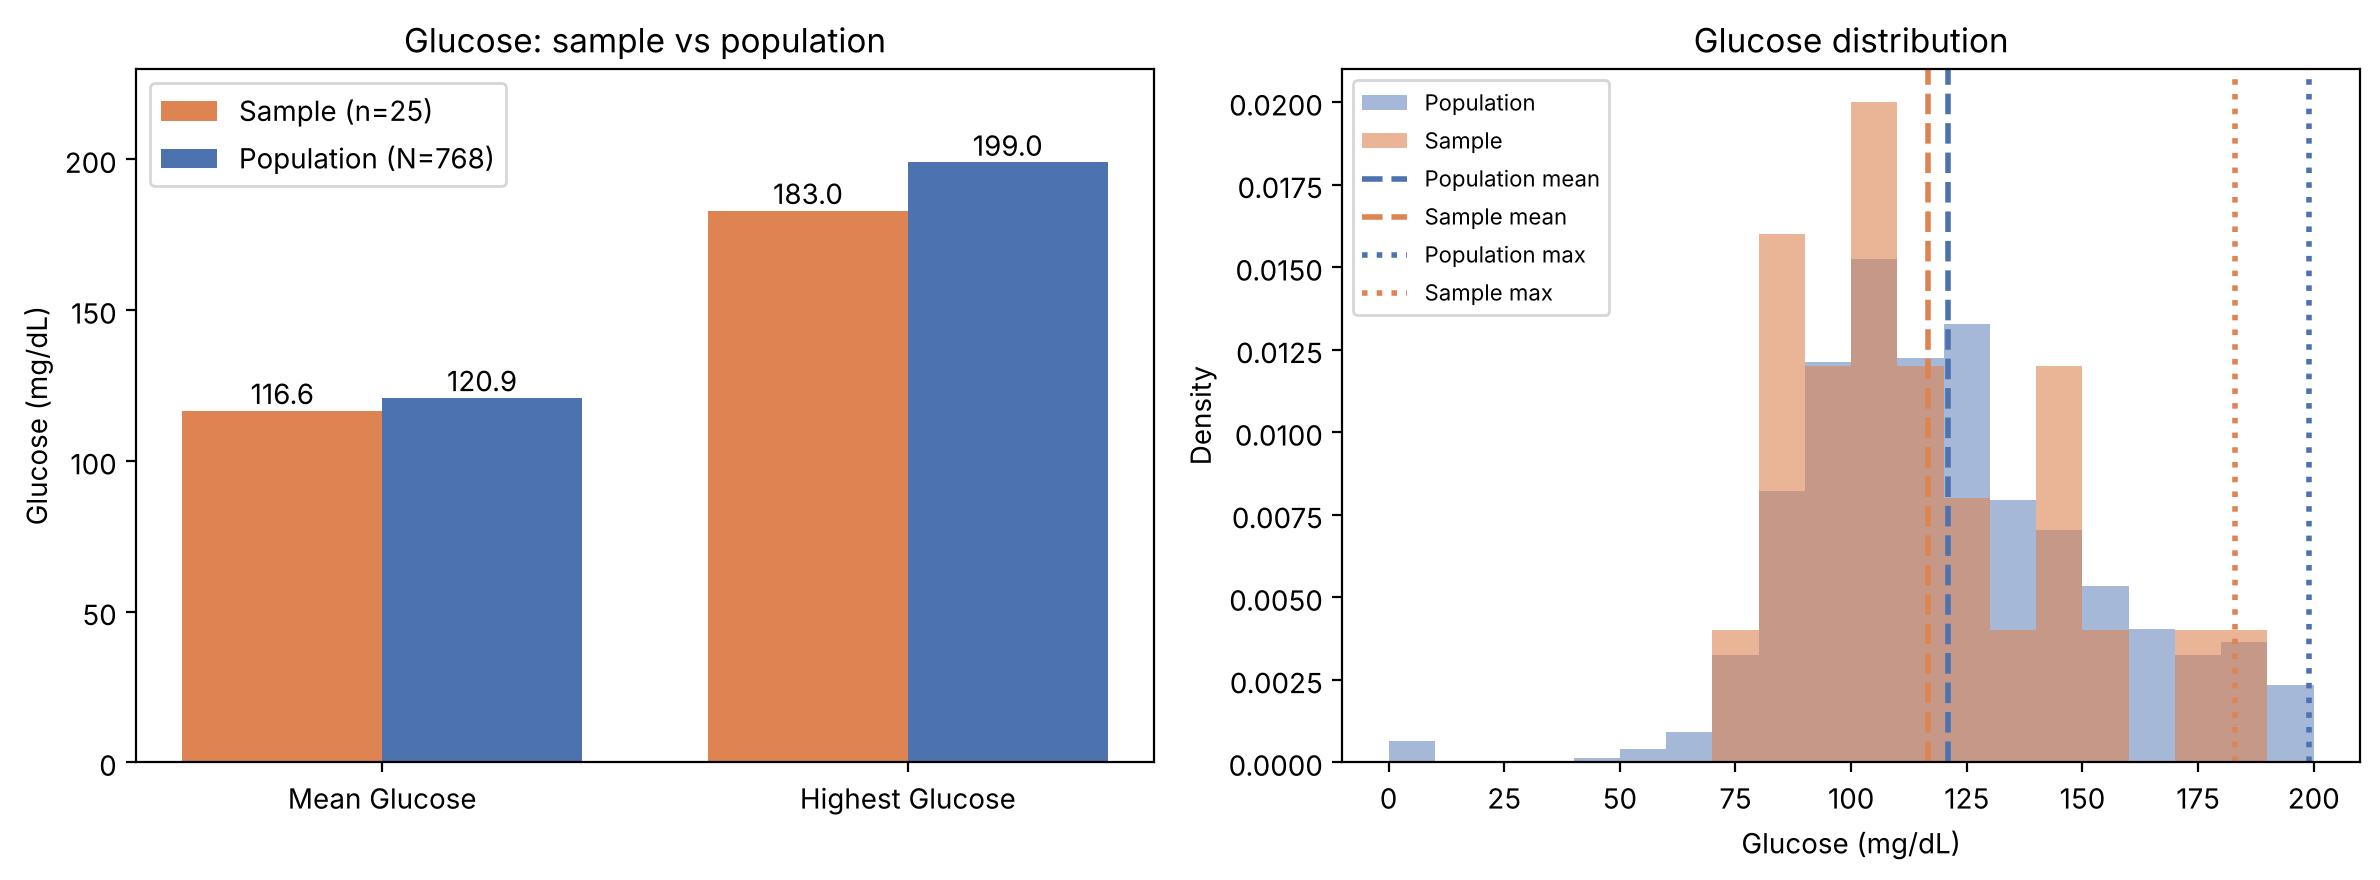

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

# Chart 1: side-by-side bars for mean and max
ax = axes[0]
x = np.arange(2)
w = 0.38
b1 = ax.bar(x - w/2, glucose_cmp["Sample (n=25)"], w, label="Sample (n=25)", color=SAMPLE_COLOR)
b2 = ax.bar(x + w/2, glucose_cmp["Population (N=768)"], w, label="Population (N=768)", color=POP_COLOR)
ax.bar_label(b1, fmt="%.1f"); ax.bar_label(b2, fmt="%.1f")
ax.set_xticks(x, glucose_cmp.index)
ax.set_ylabel("Glucose (mg/dL)")
ax.set_title("Glucose: sample vs population")
ax.legend(loc="upper left")
ax.set_ylim(0, 230)

# Chart 2: distributions with the mean and max marked
ax = axes[1]
bins = np.arange(0, 205, 10)
ax.hist(population["Glucose"], bins=bins, density=True, alpha=0.5, color=POP_COLOR, label="Population")
ax.hist(sample25["Glucose"], bins=bins, density=True, alpha=0.6, color=SAMPLE_COLOR, label="Sample")
ax.axvline(population["Glucose"].mean(), color=POP_COLOR, ls="--", lw=2, label="Population mean")
ax.axvline(sample25["Glucose"].mean(), color=SAMPLE_COLOR, ls="--", lw=2, label="Sample mean")
ax.axvline(population["Glucose"].max(), color=POP_COLOR, ls=":", lw=2, label="Population max")
ax.axvline(sample25["Glucose"].max(), color=SAMPLE_COLOR, ls=":", lw=2, label="Sample max")
ax.set_xlabel("Glucose (mg/dL)"); ax.set_ylabel("Density")
ax.set_title("Glucose distribution")
ax.legend(fontsize=8)

plt.tight_layout()
plt.show()

**Observations (a)**

* The **sample mean** (116.6) is close to the **population mean** (120.9), about 3.5% lower. With only 25 observations some random error is expected, but the mean is a stable statistic, so the estimate is reasonable.
* The **sample maximum** (183) is well below the **population maximum** (199). The maximum comes from a single extreme value, and a sample of 25 out of 768 is unlikely to include it. The sample maximum can never be higher than the population maximum, so it is a **biased (low) estimator**: small samples tend to underestimate extremes.

## (b) 98th percentile of BMI: sample vs population

`np.percentile(x, 98)` gives the value below which 98% of the observations fall. The same 25-patient sample from part (a) is used.

In [5]:
bmi_p98_sample = np.percentile(sample25["BMI"], 98)
bmi_p98_pop = np.percentile(population["BMI"], 98)

bmi_cmp = pd.DataFrame({
    "98th percentile BMI": [bmi_p98_sample, bmi_p98_pop],
}, index=["Sample (n=25)", "Population (N=768)"]).round(2)
print(f"Difference (sample - population): {bmi_p98_sample - bmi_p98_pop:.2f} "
      f"({(bmi_p98_sample - bmi_p98_pop) / bmi_p98_pop:.1%})")
bmi_cmp

Difference (sample - population): -7.28 (-15.3%)


,98th percentile BMI
Sample (n=25),40.25
Population (N=768),47.53


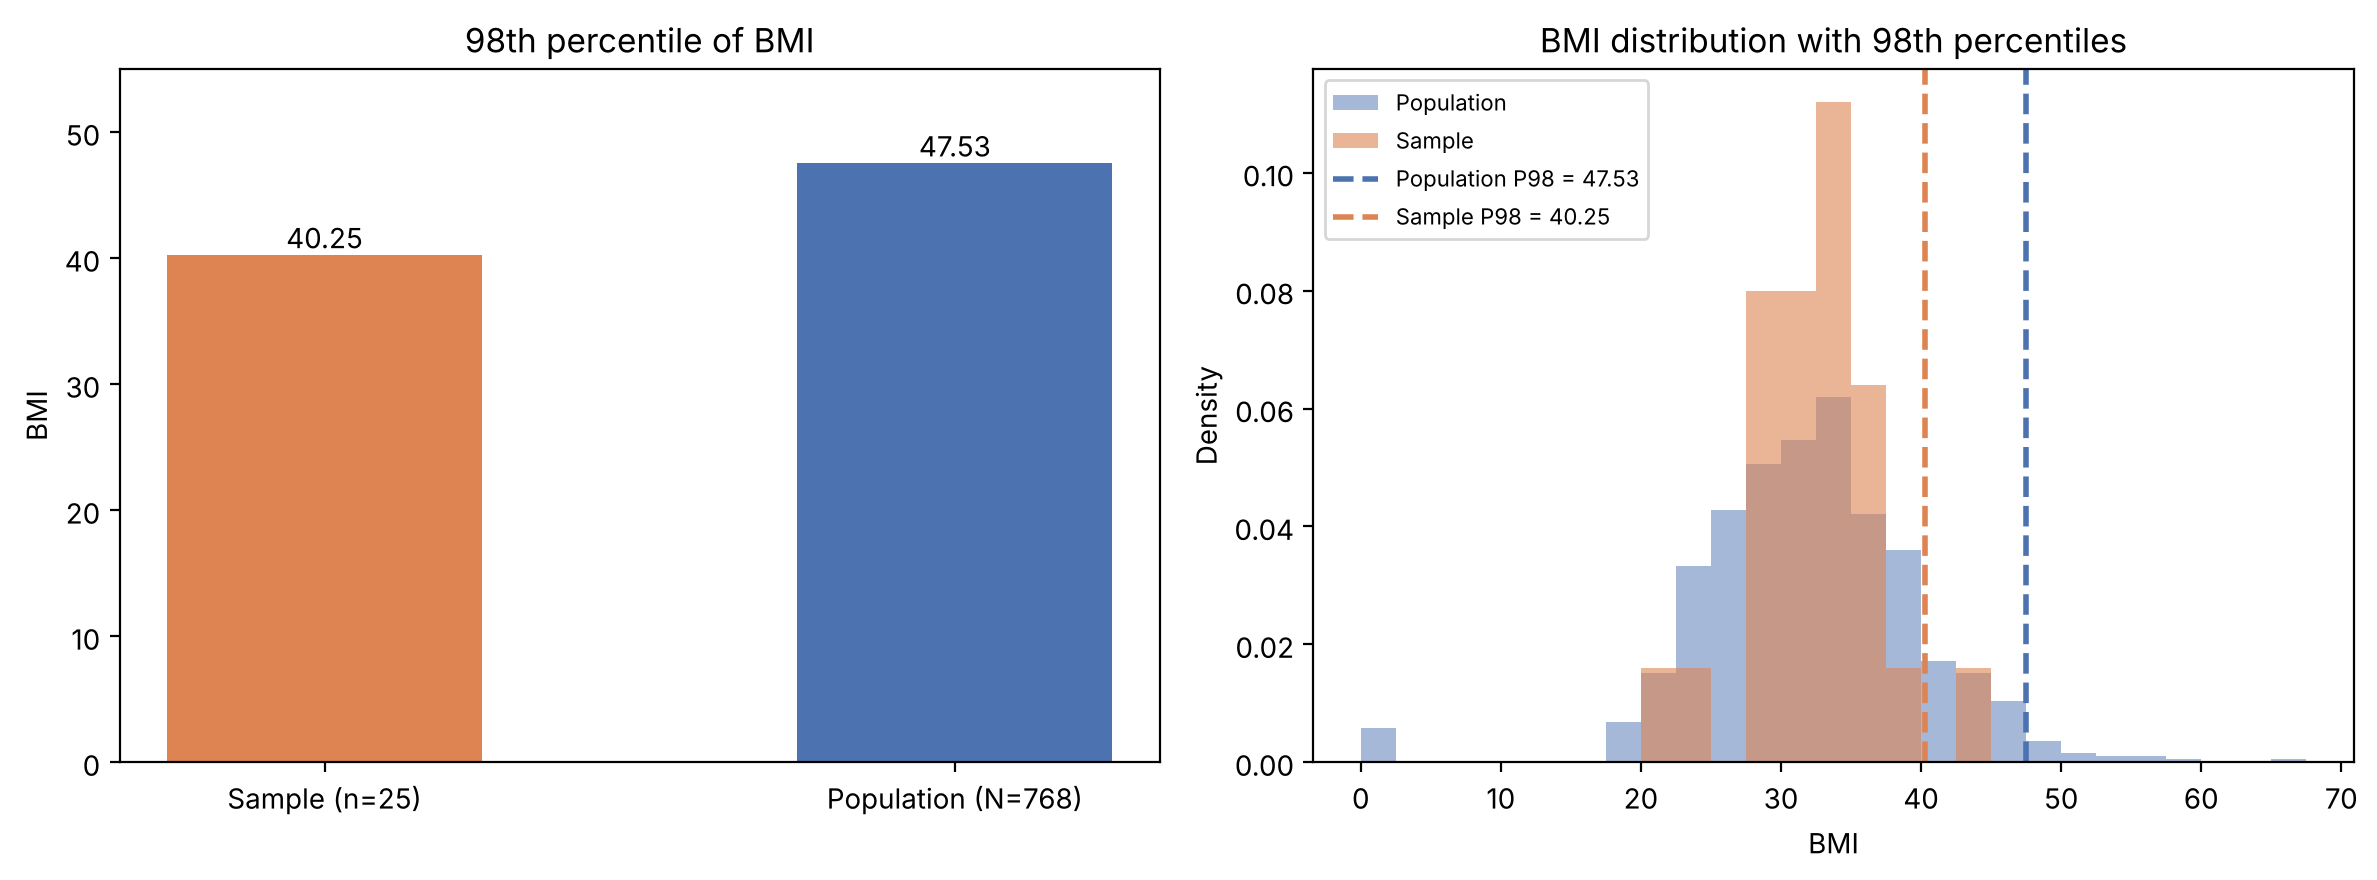

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

ax = axes[0]
bars = ax.bar(bmi_cmp.index, bmi_cmp["98th percentile BMI"], color=[SAMPLE_COLOR, POP_COLOR], width=0.5)
ax.bar_label(bars, fmt="%.2f")
ax.set_ylabel("BMI")
ax.set_ylim(0, 55)
ax.set_title("98th percentile of BMI")

ax = axes[1]
bins = np.arange(0, 70, 2.5)
ax.hist(population["BMI"], bins=bins, density=True, alpha=0.5, color=POP_COLOR, label="Population")
ax.hist(sample25["BMI"], bins=bins, density=True, alpha=0.6, color=SAMPLE_COLOR, label="Sample")
ax.axvline(bmi_p98_pop, color=POP_COLOR, ls="--", lw=2, label=f"Population P98 = {bmi_p98_pop:.2f}")
ax.axvline(bmi_p98_sample, color=SAMPLE_COLOR, ls="--", lw=2, label=f"Sample P98 = {bmi_p98_sample:.2f}")
ax.set_xlabel("BMI"); ax.set_ylabel("Density")
ax.set_title("BMI distribution with 98th percentiles")
ax.legend(fontsize=8)

plt.tight_layout()
plt.show()

**Observations (b)**

* The sample's 98th percentile BMI (**40.25**) is about **7.3 points (15%) lower** than the population's (**47.53**).
* The 98th percentile describes the extreme upper tail, so it has the same problem as the maximum in part (a). With n = 25, the "top 2%" comes down to interpolating between the one or two largest values, and the sample happened not to include the very high BMIs (50+) that exist in the population.
* Takeaway: **extreme percentiles need much larger samples** than the mean does to be estimated reliably.

## (c) Bootstrap: 500 samples of 150 BloodPressure values (with replacement)

For each of 500 iterations, draw 150 rows from the population **with replacement** (`replace=True`) and record the sample's **mean**, **standard deviation**, and **98th percentile** of `BloodPressure` (the same percentile as part (b)).
Then average each statistic across the 500 samples and compare it with the population value.

* The population standard deviation uses `ddof=0`, because the 768 rows *are* the population.
* Each bootstrap sample's standard deviation uses `ddof=1`, the usual sample estimator.

In [7]:
N_BOOT, N_SIZE, PCT = 500, 150, 98

boot_stats = []
for i in range(N_BOOT):
    bs = population.sample(n=N_SIZE, replace=True, random_state=SEED + i)["BloodPressure"]
    boot_stats.append({
        "mean": bs.mean(),
        "std": bs.std(ddof=1),
        f"p{PCT}": np.percentile(bs, PCT),
    })
boot = pd.DataFrame(boot_stats)
print(boot.shape)
boot.head()

(500, 3)


,mean,std,p98
0,71.160000,16.061158,100.00
1,70.480000,19.927627,100.16
2,67.986667,21.281743,96.04
3,67.040000,19.855478,92.04
4,70.133333,15.773424,92.16


In [8]:
bp = population["BloodPressure"]
pop_stats = pd.Series({
    "mean": bp.mean(),
    "std": bp.std(ddof=0),
    f"p{PCT}": np.percentile(bp, PCT),
})

summary = pd.DataFrame({
    "Population": pop_stats,
    "Bootstrap average (500 samples)": boot.mean(),
    "Bootstrap 2.5th pct": boot.quantile(0.025),
    "Bootstrap 97.5th pct": boot.quantile(0.975),
    "Bootstrap SD (spread)": boot.std(ddof=1),
})
summary["Difference (boot avg - pop)"] = summary["Bootstrap average (500 samples)"] - summary["Population"]
summary["% difference"] = summary["Difference (boot avg - pop)"] / summary["Population"] * 100
summary.index = ["Mean", "Standard deviation", f"{PCT}th percentile"]
summary.round(2)

,Population,Bootstrap average (500 samples),Bootstrap 2.5th pct,Bootstrap 97.5th pct,Bootstrap SD (spread),Difference (boot avg - pop),% difference
Mean,69.11,69.18,65.93,72.15,1.61,0.07,0.10
Standard deviation,19.34,19.17,14.76,23.17,2.13,-0.17,-0.90
98th percentile,99.32,98.25,90.14,108.04,4.89,-1.07,-1.07


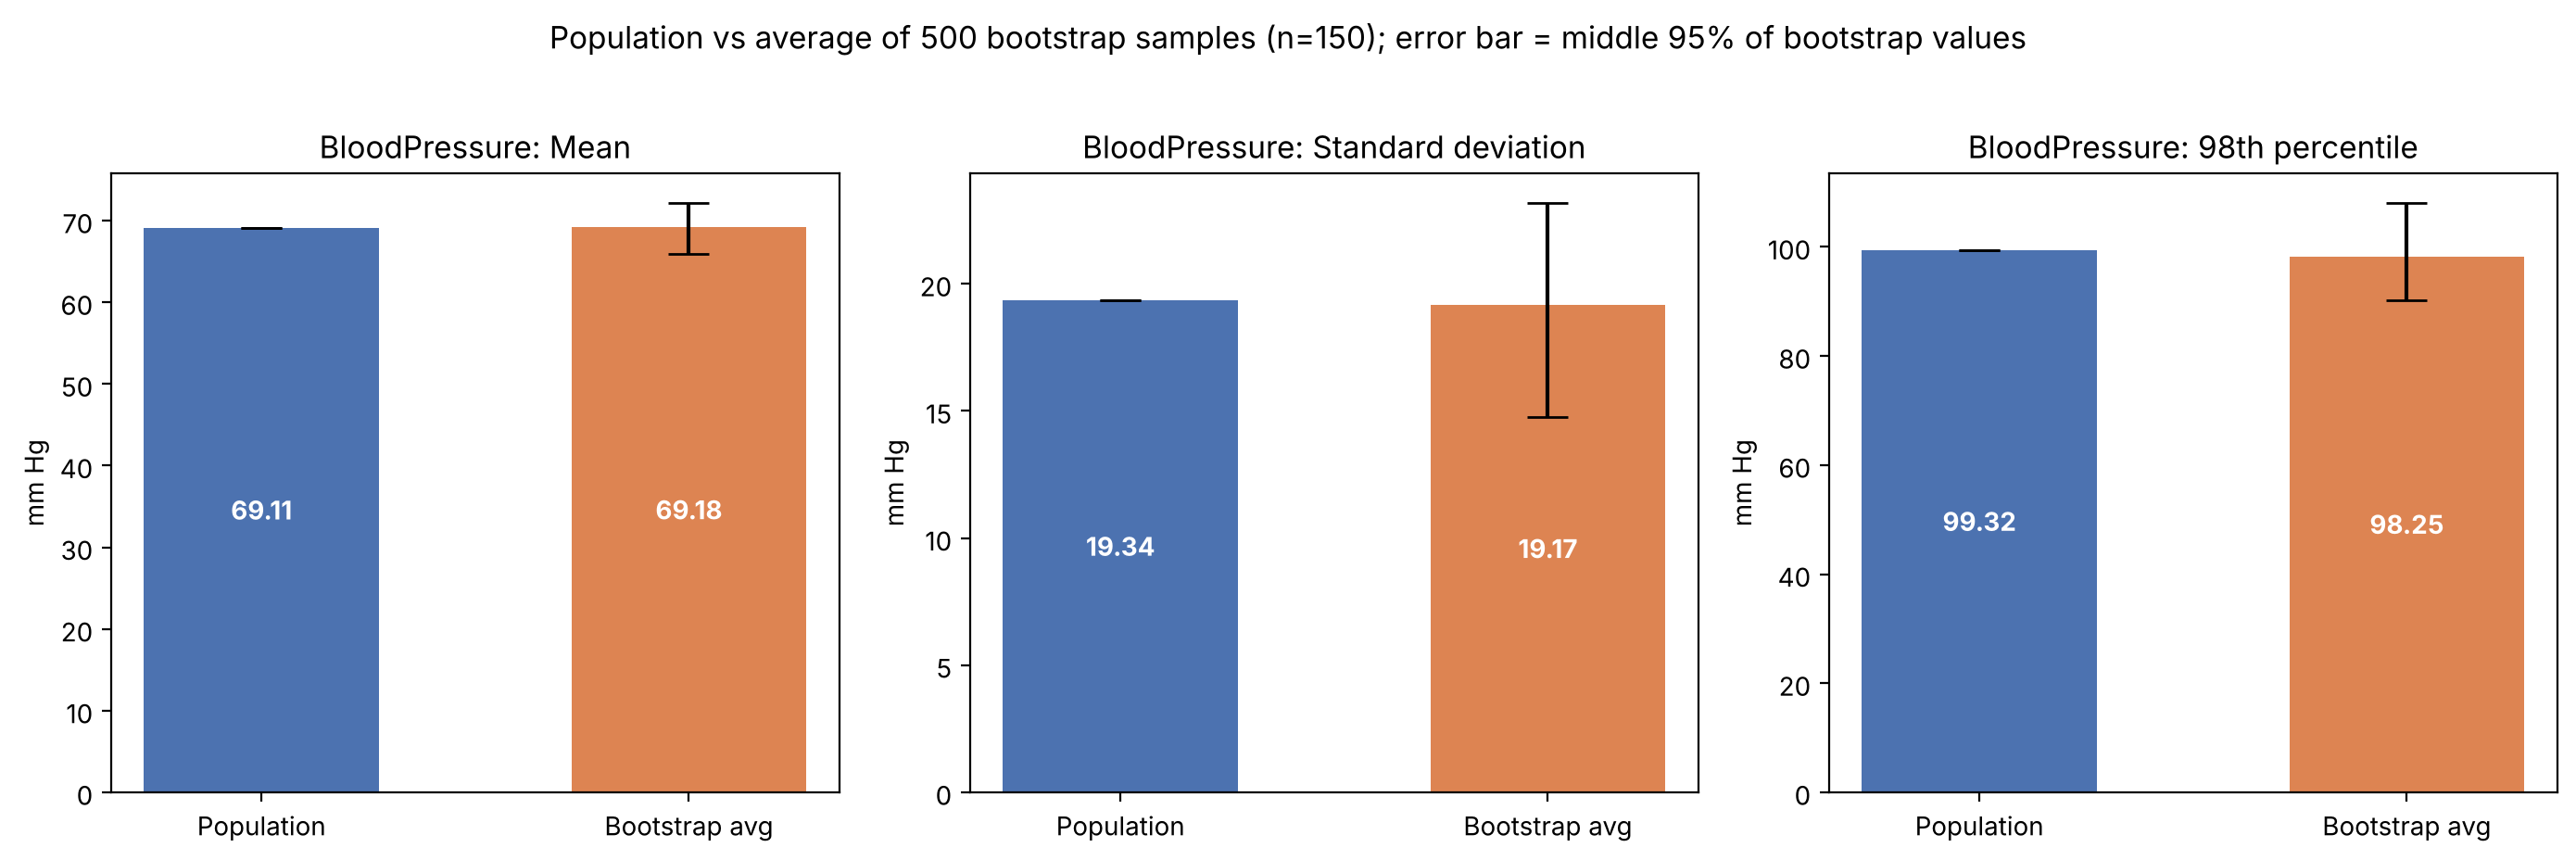

In [9]:
# Chart 1: population vs bootstrap average for each statistic (separate panels because scales differ).
# Error bars show the middle 95% of the 500 bootstrap values.
fig, axes = plt.subplots(1, 3, figsize=(14, 4.5))
for ax, (label, row) in zip(axes, summary.iterrows()):
    vals = [row["Population"], row["Bootstrap average (500 samples)"]]
    err_lo = [0, vals[1] - row["Bootstrap 2.5th pct"]]
    err_hi = [0, row["Bootstrap 97.5th pct"] - vals[1]]
    bars = ax.bar(["Population", "Bootstrap avg"], vals, color=[POP_COLOR, SAMPLE_COLOR],
                  yerr=[err_lo, err_hi], capsize=8, width=0.55)
    ax.bar_label(bars, labels=[f"{v:.2f}" for v in vals], label_type="center", color="white", fontweight="bold")
    ax.set_title(f"BloodPressure: {label}")
    ax.set_ylabel("mm Hg")
fig.suptitle("Population vs average of 500 bootstrap samples (n=150); error bar = middle 95% of bootstrap values", y=1.02)
plt.tight_layout()
plt.show()

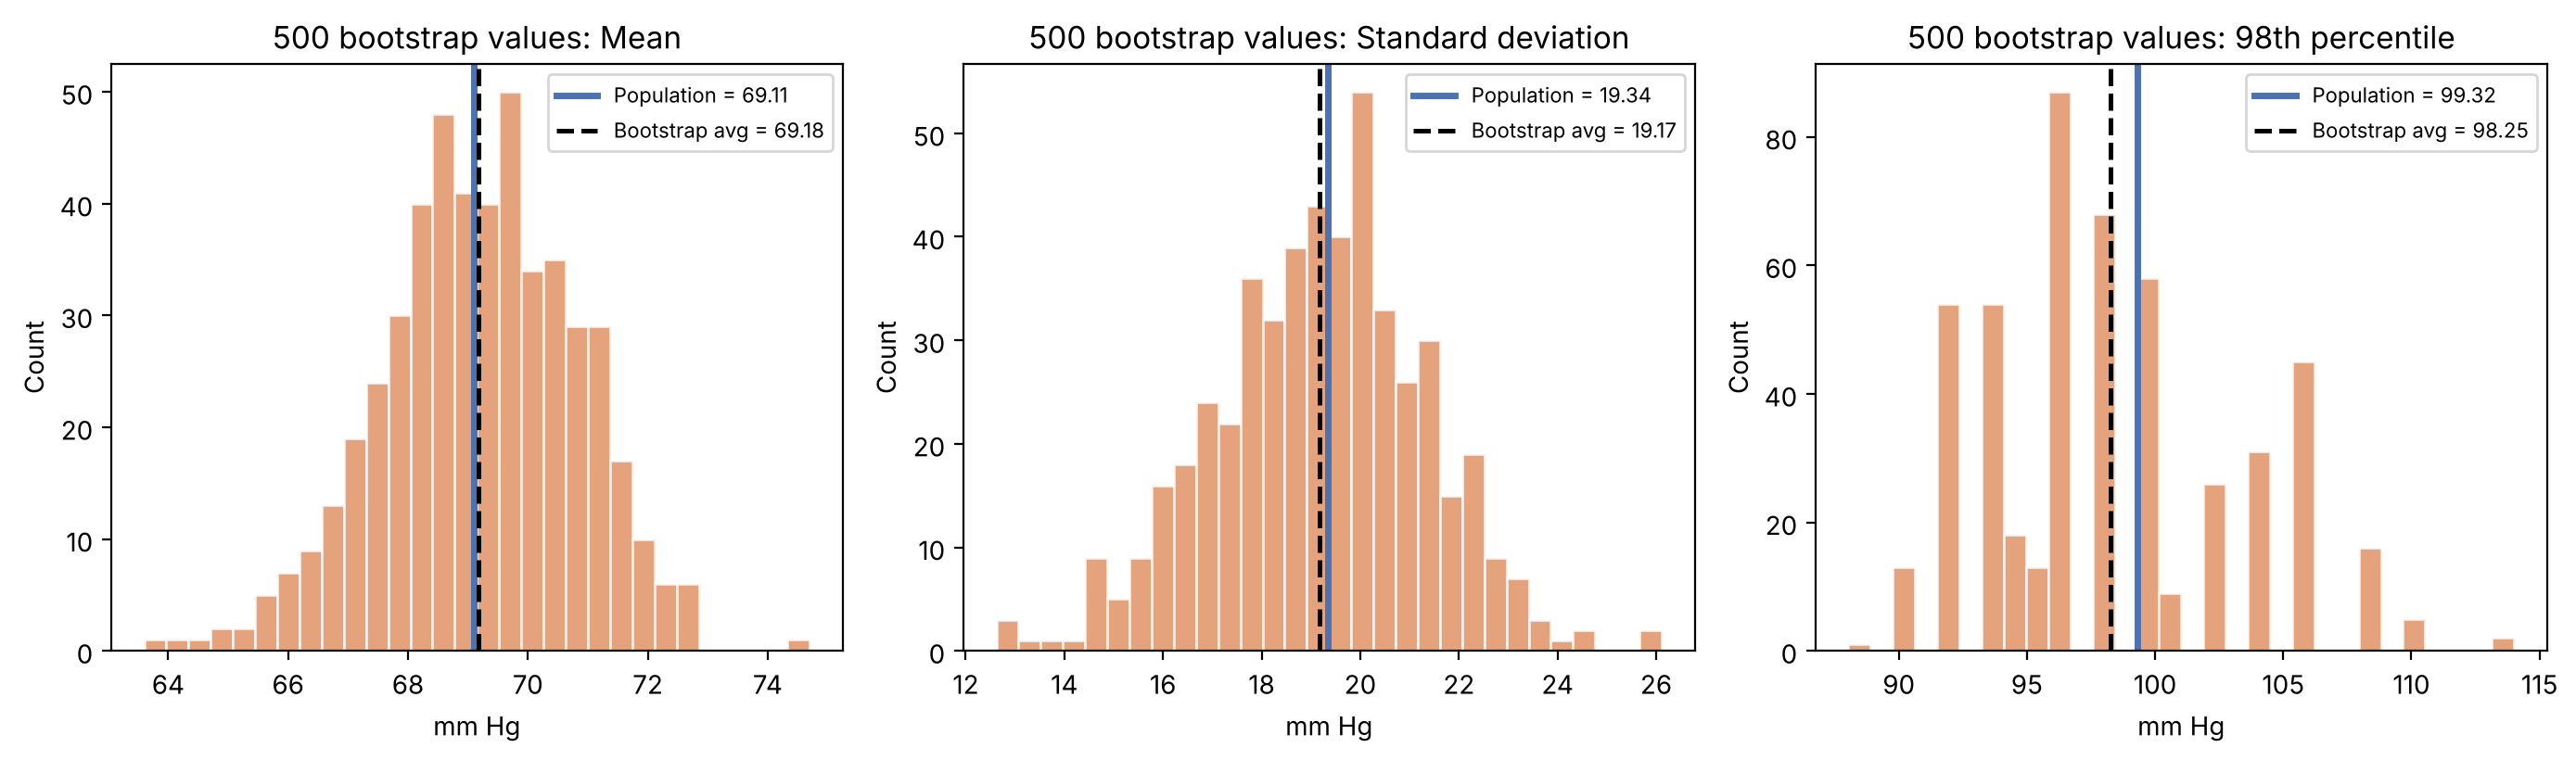

In [10]:
# Chart 2: sampling distributions of each statistic across the 500 bootstrap samples.
fig, axes = plt.subplots(1, 3, figsize=(14, 4.2))
for ax, col, label in zip(axes, boot.columns, summary.index):
    ax.hist(boot[col], bins=30, color=SAMPLE_COLOR, alpha=0.75, edgecolor="white")
    ax.axvline(pop_stats[col], color=POP_COLOR, lw=2.5, label=f"Population = {pop_stats[col]:.2f}")
    ax.axvline(boot[col].mean(), color="black", ls="--", lw=1.8, label=f"Bootstrap avg = {boot[col].mean():.2f}")
    ax.set_title(f"500 bootstrap values: {label}")
    ax.set_xlabel("mm Hg"); ax.set_ylabel("Count")
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

In [11]:
# Context for the findings: the population contains impossible 0 readings for blood pressure.
zeros = (bp == 0).sum()
print(f"BloodPressure == 0 in the population: {zeros} of {len(bp)} ({zeros / len(bp):.1%})")
print(f"Standard error of the mean, theory sigma/sqrt(n): {bp.std(ddof=0) / np.sqrt(N_SIZE):.2f}")
print(f"Standard error of the mean, bootstrap SD of means: {boot['mean'].std(ddof=1):.2f}")

BloodPressure == 0 in the population: 35 of 768 (4.6%)
Standard error of the mean, theory sigma/sqrt(n): 1.58
Standard error of the mean, bootstrap SD of means: 1.61


## Findings

| Statistic | Population | Bootstrap average | Middle 95% of bootstrap values |
|---|---|---|---|
| Mean | 69.11 | 69.18 | 65.93 – 72.15 |
| Standard deviation | 19.34 | 19.17 | 14.76 – 23.17 |
| 98th percentile | 99.32 | 98.25 | 90.14 – 108.04 |

1. **Mean: almost no bias.** The average of the 500 bootstrap means (69.18) is within 0.1 mm Hg of the population mean (69.11). The sample mean is an unbiased estimator. The 500 means form a roughly normal, bell-shaped distribution centred on the true value, as the Central Limit Theorem predicts. Its spread (bootstrap SE ≈ 1.61) matches the theoretical σ/√n ≈ 1.58.
2. **Standard deviation: close, slightly low.** The average bootstrap SD (19.17) is about 0.9% below the population SD (19.34). Even with `ddof=1`, the sample SD is slightly biased downward. The SD values also spread much more widely (about 14.8 to 23.2) than the means do. This is likely because the population includes **35 impossible readings of 0 mm Hg**. Whether a sample happens to draw several of these outliers can have a large effect on its SD.
3. **98th percentile: more variable and biased low.** The bootstrap average (98.25) is about 1.1 mm Hg (1.1%) below the population value (99.32), and individual samples range from about 90 to 108. With 150 values, the 98th percentile depends on only the top 3 observations, so it is noisy and tends to underestimate the tail. This matches what parts (a) and (b) showed for the maximum and the 98th-percentile BMI.
4. **Overall:** with samples of 150, averaging over many bootstrap samples recovers the population **mean very accurately**, the **SD well**, and the **extreme percentile less reliably**. Statistics based on the centre of a distribution are estimated much more precisely than statistics based on its tails. The bootstrap also shows *how uncertain* each estimate is, which a single sample cannot show.
5. **Data-quality note:** the zero readings (as well as zeros in Glucose, BMI, SkinThickness, and Insulin) are really missing values. Because this data is treated as a population, they were kept as-is. Removing them would raise the mean blood pressure and shrink its SD.